# 01 · Exploratory data analysis: Onsite data (first batch)

**Goal:** understand what each of the four classes looks like before building a model.

All data is read from the database (`files` table) and from `processed/` in `URECA_DATA_ROOT`. Nothing here writes or changes data.

| Part | Question |
|---|---|
| 0 | Setup |
| 1 | How much data is there, and when was it recorded? |
| 2 | What does the recording hardware tell us? |
| 3 | What does a typical waveform of each class look like? |
| 4 | What happens around the trigger point? |
| 5 | How consistent is each class? (5b: switching noise by session) |
| 6 | Amplitude: how large are the signals? |
| 7 | Shape: is it one sharp spike or a long burst? |
| 8 | Frequency content |
| 9 | Time–frequency view (spectrograms) |
| 10 | Summary and what it means for modelling |

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from ureca.db import connect
from ureca.config import ensure_dirs

FS = 125e6                      # sampling rate, samples per second
DT_US = 1e6 / FS                # 0.008 µs per sample

# Classes in a fixed order, each with a fixed colour and marker (used in every plot).
CLASSES = ["partial_discharge", "switching_noise", "transient_noise", "spark_lighter"]
NAMES   = {"partial_discharge": "Partial discharge", "switching_noise": "Switching noise",
           "transient_noise": "Transient noise", "spark_lighter": "Spark lighter"}
COLORS  = {"partial_discharge": "#2a78d6", "switching_noise": "#eb6834",
           "transient_noise": "#1baf7a", "spark_lighter": "#eda100"}
MARKERS = {"partial_discharge": "o", "switching_noise": "s",
           "transient_noise": "^", "spark_lighter": "D"}

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9, "axes.titlesize": 10,
    "lines.linewidth": 1.0, "legend.frameon": False,
})

def legend_handles(classes=CLASSES, marker=True):
    return [Line2D([], [], color=COLORS[c], marker=MARKERS[c] if marker else None,
                   linestyle="" if marker else "-", markersize=7, label=NAMES[c]) for c in classes]

In [2]:
proc = ensure_dirs()["processed"]
with connect() as conn:
    df = pd.read_sql("SELECT * FROM files WHERE status = 'ok'", conn)

df["label"] = pd.Categorical(df["label"], CLASSES, ordered=True)
df["ts"] = pd.to_datetime(df["timestamp"])
df = df.sort_values(["label", "ts"]).reset_index(drop=True)

# Load every waveform into one array: shape (n_files, 16384)
X = np.stack([np.loadtxt(proc / p) for p in df["raw_path"]])
t_us = np.arange(X.shape[1]) * DT_US

print(f"Loaded {X.shape[0]} waveforms x {X.shape[1]} samples  ({X.nbytes / 1e6:.1f} MB as float64)")

Loaded 167 waveforms x 16384 samples  (21.9 MB as float64)


## 1. How much data is there, and when was it recorded?

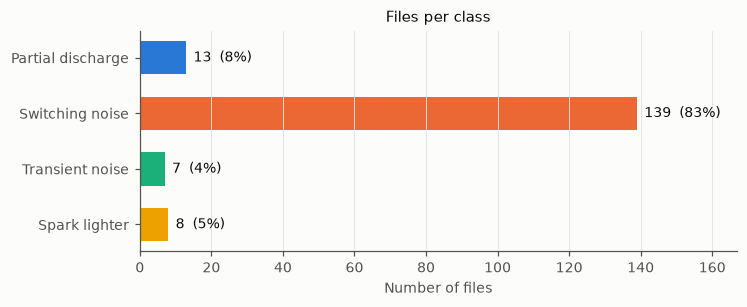

In [3]:
counts = df["label"].value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(len(CLASSES))[::-1]
ax.barh(y, counts.values, color=[COLORS[c] for c in CLASSES], height=0.6)
for yi, n in zip(y, counts.values):
    ax.text(n + 2, yi, f"{n}  ({n / counts.sum():.0%})", va="center", color=INK)
ax.set_yticks(y, [NAMES[c] for c in CLASSES])
ax.set_xlabel("Number of files")
ax.set_title("Files per class")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.max() * 1.2)
plt.show()

**Explanation:** the dataset is **very imbalanced**. Switching noise makes up about 83% of the files, while the other three classes have only 7–13 files each. A model that always answers "switching noise" would already be 83% accurate, so **accuracy is a misleading score here**. Use per-class recall, macro-F1 or a confusion matrix, and use class weights or resampling during training.

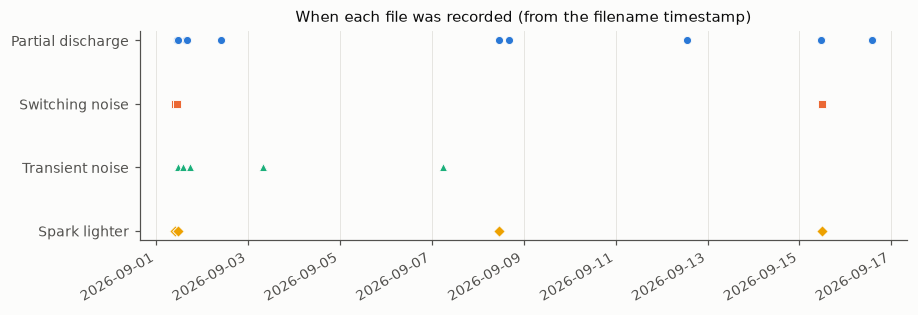

In [4]:
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, c in enumerate(CLASSES):
    g = df[df["label"] == c]
    ax.scatter(g["ts"], np.full(len(g), len(CLASSES) - 1 - i), color=COLORS[c],
               marker=MARKERS[c], s=28, edgecolor="#fcfcfb", linewidth=0.6, zorder=3)
ax.set_yticks(range(len(CLASSES))[::-1], [NAMES[c] for c in CLASSES])
ax.set_title("When each file was recorded (from the filename timestamp)")
ax.grid(axis="y", visible=False)
fig.autofmt_xdate()
plt.show()

In [5]:
# Files recorded exactly 1 second apart are treated as one "recording session" (a burst).
def sessions(g):
    t = g["ts"].sort_values()
    return (t.diff().dt.total_seconds().ne(1)).cumsum()

df["session"] = df.groupby("label", observed=True, group_keys=False).apply(sessions)
summary = df.groupby("label", observed=True).agg(
    files=("file_id", "size"),
    days=("ts", lambda s: s.dt.date.nunique()),
    sessions=("session", "nunique"),
    largest_session=("session", lambda s: s.value_counts().max()),
)
summary.index = [NAMES[c] for c in summary.index]
summary

,files,days,sessions,largest_session
Partial discharge,13,6,13,1
Switching noise,139,2,4,61
Transient noise,7,3,6,2
Spark lighter,8,3,5,3


**Explanation:** the files were collected on a few days in September 2026. Switching noise was recorded in **only 4 bursts** (two of them are really one recording with a single missing second): the capture ran once per second for up to a minute each time. Every other class has at most 3 files per burst. This means many switching-noise files are near-copies of their neighbours.

⚠️ **Data-leakage risk:** if the train/val/test split is random, files from the same burst end up on both sides and the test score will look better than it really is. Split by **session** (or by day), not by file. The README's split-assignment step should do this.

## 2. What does the recording hardware tell us?

Each file holds 16,384 samples at 125 MS/s, which is about 131 µs of signal. Below we check the voltage resolution, the baseline offset and **where in the window the largest peak falls**.

In [6]:
step = np.median([np.diff(np.unique(x)).min() for x in X])
baseline = np.median(X, axis=1)
peak_idx = np.abs(X - baseline[:, None]).argmax(axis=1)

print(f"Smallest voltage step : {step * 1e3:.3f} mV   ->  2 V / {2 / step:,.0f} levels  (~{np.log2(2 / step):.0f}-bit over ±1 V)")
print(f"Baseline (median)     : {baseline.min() * 1e3:.2f} to {baseline.max() * 1e3:.2f} mV")
print(f"Max |value| anywhere  : {np.abs(X).max():.3f} V")

Smallest voltage step : 0.122 mV   ->  2 V / 16,393 levels  (~14-bit over ±1 V)
Baseline (median)     : -0.37 to 3.91 mV
Max |value| anywhere  : 1.054 V


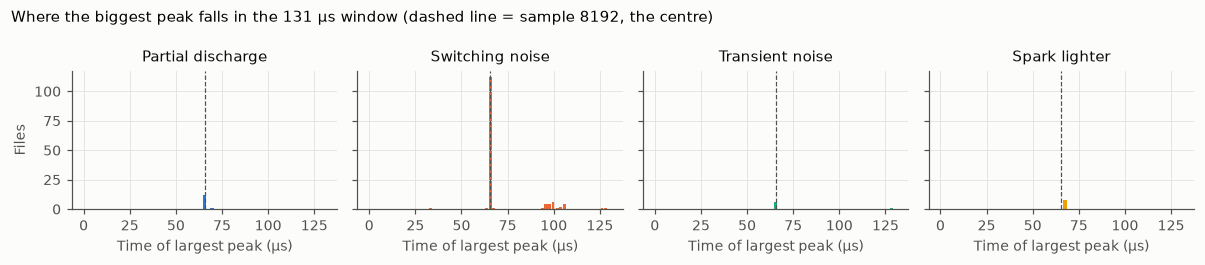

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.4), sharey=True)
bins = np.linspace(0, t_us[-1], 66)
for ax, c in zip(axes, CLASSES):
    m = (df["label"] == c).values
    ax.hist(peak_idx[m] * DT_US, bins=bins, color=COLORS[c], rwidth=0.85)
    ax.axvline(8192 * DT_US, color=INK2, linestyle="--", linewidth=0.8)
    ax.set_title(NAMES[c])
    ax.set_xlabel("Time of largest peak (µs)")
axes[0].set_ylabel("Files")
fig.suptitle("Where the biggest peak falls in the 131 µs window (dashed line = sample 8192, the centre)", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

**Explanation:**
- Values move in steps of about 0.12 mV, which equals ±1 V split into 16,384 levels (a 14-bit ADC). This explains why **spark-lighter files clip at ±1.0 V**: the signal goes beyond what the ADC can measure.
- The baseline is close to 0 V (within a few mV), so no offset correction is needed.
- In almost every file the largest peak sits at **sample 8192, the centre of the window**. The oscilloscope is triggered by the event and keeps half the window before it and half after. All waveforms are already **time-aligned**, which makes them easy to compare and easy for a model to learn from. A few switching-noise files peak at about 95–105 µs instead. That is one switching period (~33 µs, see Part 3) after the trigger, where the next burst happened to be larger.

## 3. What does a typical waveform of each class look like?

Three files per class (first, middle and last by time), shown over the full 131 µs window. **Each row has its own y-axis scale**, because the amplitudes differ by more than 10×.

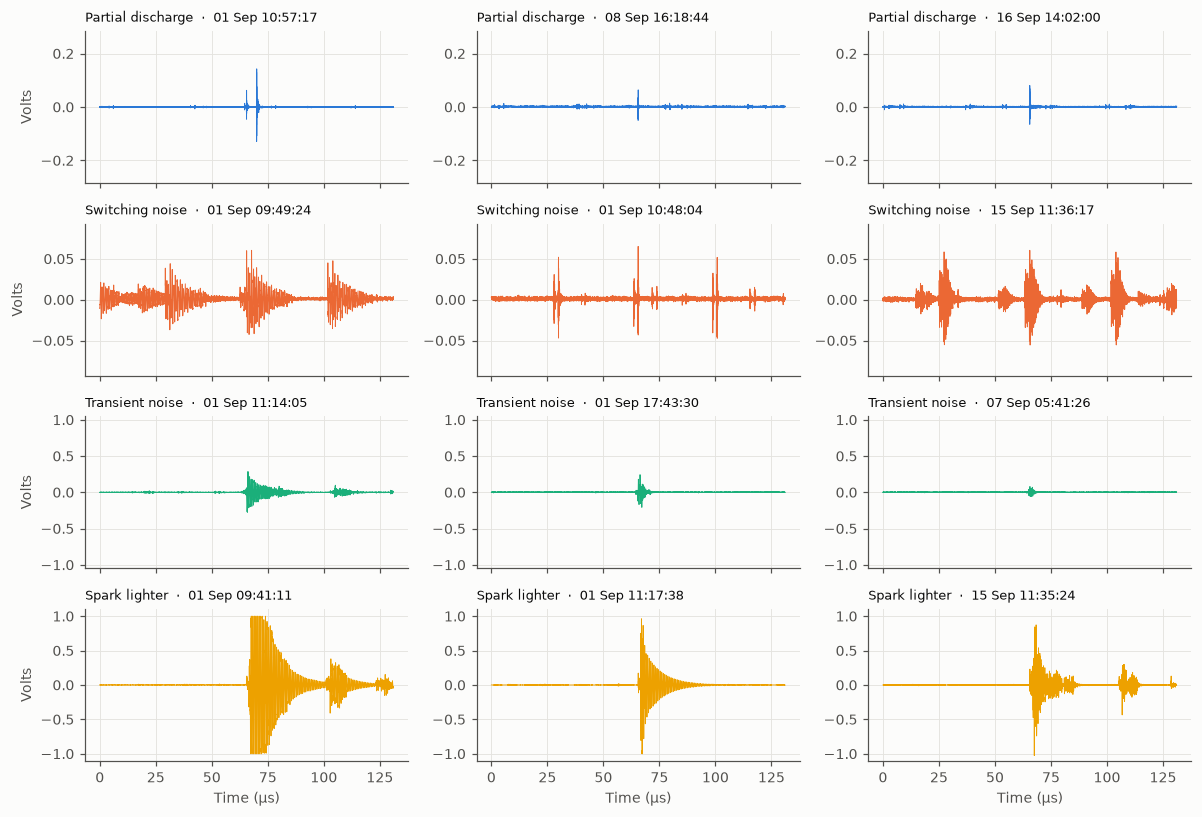

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(11, 7.5), sharex=True)
for r, c in enumerate(CLASSES):
    idx = np.flatnonzero((df["label"] == c).values)
    picks = idx[[0, len(idx) // 2, -1]]
    lim = np.abs(X[idx]).max() * 1.05
    for k, i in enumerate(picks):
        ax = axes[r, k]
        ax.plot(t_us, X[i], color=COLORS[c], linewidth=0.6)
        ax.set_ylim(-lim, lim)
        ax.set_title(f"{NAMES[c]}  ·  {df.loc[i, 'ts']:%d %b %H:%M:%S}", fontsize=8.5, loc="left")
        if k == 0: ax.set_ylabel("Volts")
for ax in axes[-1]: ax.set_xlabel("Time (µs)")
plt.tight_layout(); plt.show()

**Explanation:**
- **Partial discharge:** a single sharp spike at the trigger point, with almost nothing else in the window. It is short and isolated.
- **Switching noise:** **bursts that repeat about every 31–39 µs** (3–4 per window, which means ~25–33 kHz), each with a peak of about 0.06 V. This regular repetition is typical of power-electronics switching. The burst shape differs between recording sessions (Part 5b).
- **Transient noise:** a larger, longer disturbance that rings and decays after the trigger. Its size varies a lot between files.
- **Spark lighter:** a very large event that **saturates at ±1 V** and keeps ringing for many microseconds.

## 4. What happens around the trigger point?

The same files, zoomed in to **−2 µs … +8 µs** around sample 8192. This shows the shape of the event itself.

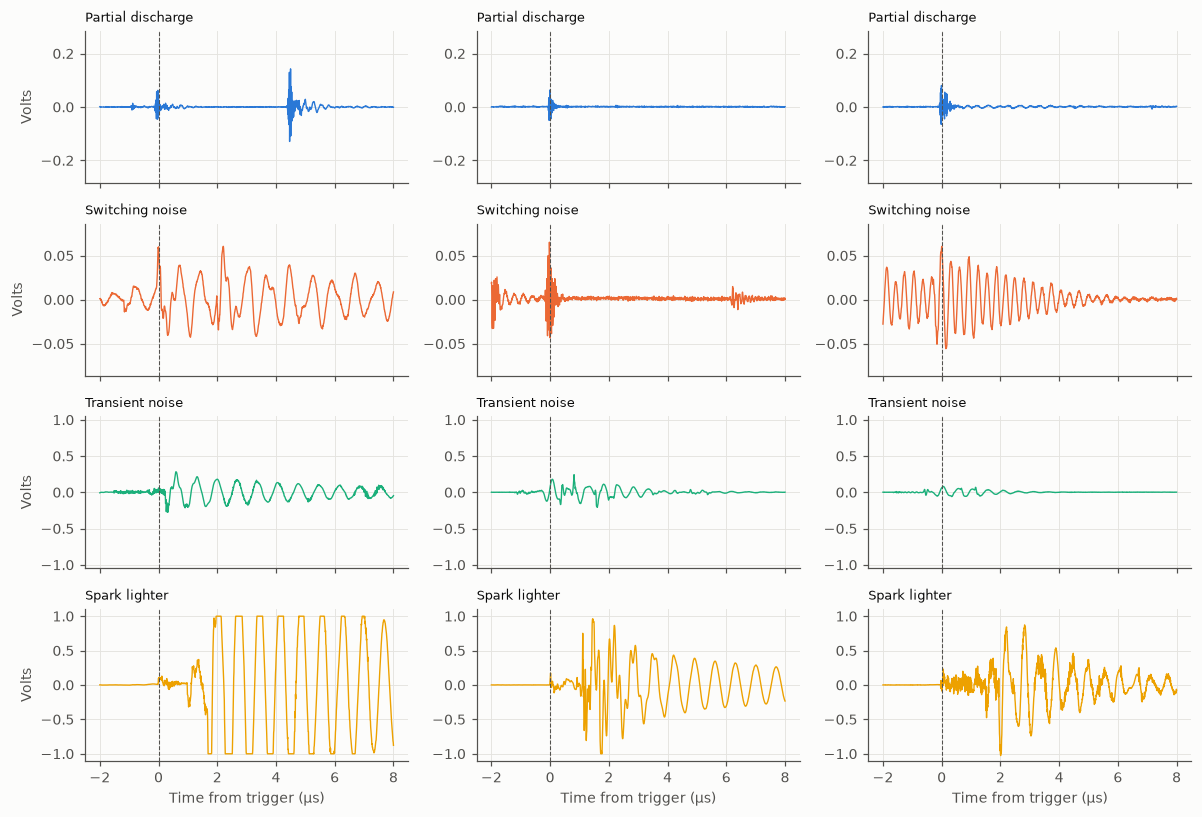

In [9]:
win = (t_us >= 8192 * DT_US - 2) & (t_us <= 8192 * DT_US + 8)
tz = t_us[win] - 8192 * DT_US
fig, axes = plt.subplots(4, 3, figsize=(11, 7.5), sharex=True)
for r, c in enumerate(CLASSES):
    idx = np.flatnonzero((df["label"] == c).values)
    picks = idx[[0, len(idx) // 2, -1]]
    lim = np.abs(X[idx][:, win]).max() * 1.05
    for k, i in enumerate(picks):
        ax = axes[r, k]
        ax.plot(tz, X[i, win], color=COLORS[c], linewidth=0.9)
        ax.axvline(0, color=INK2, linestyle="--", linewidth=0.7)
        ax.set_ylim(-lim, lim)
        ax.set_title(NAMES[c], fontsize=8.5, loc="left")
        if k == 0: ax.set_ylabel("Volts")
for ax in axes[-1]: ax.set_xlabel("Time from trigger (µs)")
plt.tight_layout(); plt.show()

**Explanation:** zoomed in, the classes separate clearly.
- **Partial discharge** is a fast pulse lasting well under 1 µs, followed by a short, quickly damped ring. Sometimes a second pulse follows a few µs later (top-left), which is common for PD.
- **Switching noise** starts with a sharp edge at the trigger, followed by a damped oscillation of roughly 1–3 MHz.
- **Transient noise** rings at a low frequency (around 2 MHz) and decays within a few µs.
- **Spark lighter** shows a small precursor at the trigger, and **the main discharge arrives about 1–2 µs later**. It then swings so hard that it is flattened at ±1 V (clipping) and rings for tens of µs.

The fine detail near the trigger is probably what a model will rely on most.

## 5. How consistent is each class?

All files of a class are overlaid in the zoomed window (thin lines). The dark line is the **median across files** and the shaded band covers the 10th–90th percentile.

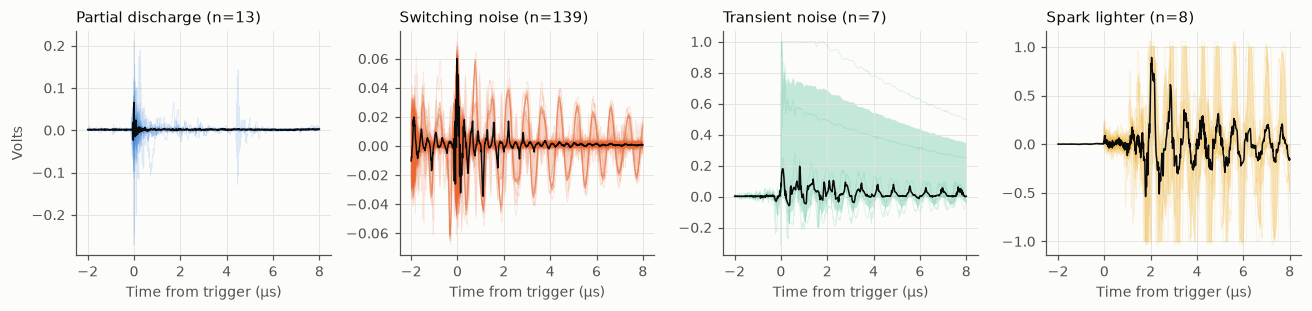

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.9), sharex=True)
for ax, c in zip(axes, CLASSES):
    W = X[(df["label"] == c).values][:, win]
    for w in W[:60]:
        ax.plot(tz, w, color=COLORS[c], alpha=0.15, linewidth=0.5)
    lo, med, hi = np.percentile(W, [10, 50, 90], axis=0)
    ax.fill_between(tz, lo, hi, color=COLORS[c], alpha=0.25, linewidth=0)
    ax.plot(tz, med, color=INK, linewidth=1.0)
    ax.set_title(f"{NAMES[c]} (n={len(W)})", loc="left")
    ax.set_xlabel("Time from trigger (µs)")
axes[0].set_ylabel("Volts")
plt.tight_layout(); plt.show()

**Explanation:**
- **Switching noise** is very repeatable: the 139 files nearly overlap. This fits the burst recording found in Part 1, and it means there is less real variety than the count of 139 suggests.
- **Partial discharge** has a consistent pulse position and shape, but its height varies.
- **Transient noise** and **spark lighter** vary the most from file to file (the transient band is stretched upward by its two largest files). With only 7–8 examples each, the model will see little of that variation. Collecting more of these two classes would help the most.

### 5b. Switching noise: does it differ between recording sessions?
Switching noise is 83% of the data but comes from only a few sessions, so we check whether those sessions look alike.

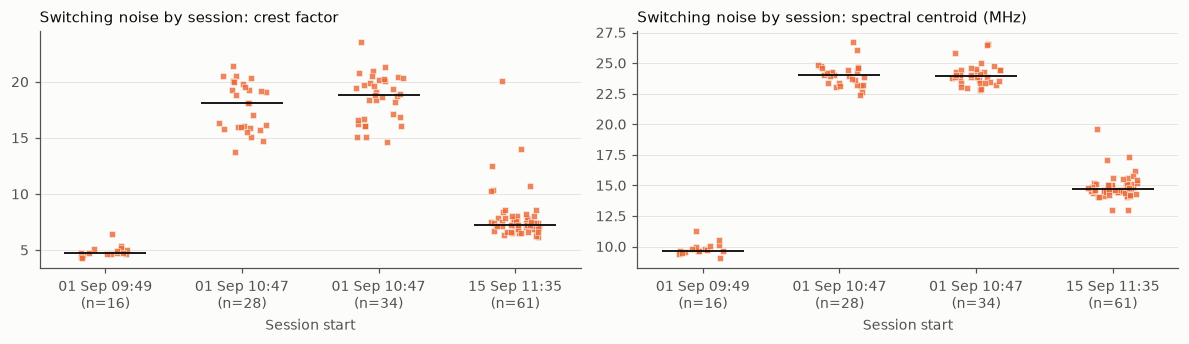

In [11]:
sw = df[df["label"] == "switching_noise"].copy()
D_sw = X[sw.index] - np.median(X[sw.index], axis=1, keepdims=True)
sw["crest"] = np.abs(D_sw).max(axis=1) / D_sw.std(axis=1)
F_sw = np.abs(np.fft.rfft(D_sw, axis=1))
f_sw = np.fft.rfftfreq(X.shape[1], 1 / FS) / 1e6
sw["centroid_MHz"] = (F_sw * f_sw).sum(axis=1) / F_sw.sum(axis=1)

groups = list(sw.groupby("session"))
labels = [f"{g['ts'].min():%d %b %H:%M}\n(n={len(g)})" for _, g in groups]
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col, title in zip(axes, ["crest", "centroid_MHz"], ["crest factor", "spectral centroid (MHz)"]):
    for i, (_, g) in enumerate(groups):
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(g)), g[col], s=16, color=COLORS["switching_noise"],
                   marker="s", alpha=0.8, edgecolor="#fcfcfb", linewidth=0.4, zorder=3)
        ax.hlines(g[col].median(), i - 0.3, i + 0.3, color=INK, linewidth=1.2, zorder=4)
    ax.set_xticks(range(len(groups)), labels); ax.grid(axis="x", visible=False)
    ax.set_title(f"Switching noise by session: {title}", loc="left"); ax.set_xlabel("Session start")
plt.tight_layout(); plt.show()

**Explanation:** each session has its **own signature**. The 1 Sep 09:49 session has a low crest factor and a low centroid (~10 MHz). The two 1 Sep 10:47 sessions (really one recording) have a high crest factor and a centroid of ~24 MHz. The 15 Sep session sits in between. Switching noise is therefore really **about 3 different noise sources**, not 139 independent examples.

This matters for evaluation: if one session is held out for testing, the model must handle a switching pattern it has never seen, which is a much more honest test. It also confirms that splitting by session is the right choice.

## 6. Amplitude: how large are the signals?

Simple statistics for each file, measured from its own baseline (median):
- **peak** = largest |deviation|
- **RMS** = overall energy level across the whole window
- **clipped** = share of samples at the ±1 V limit

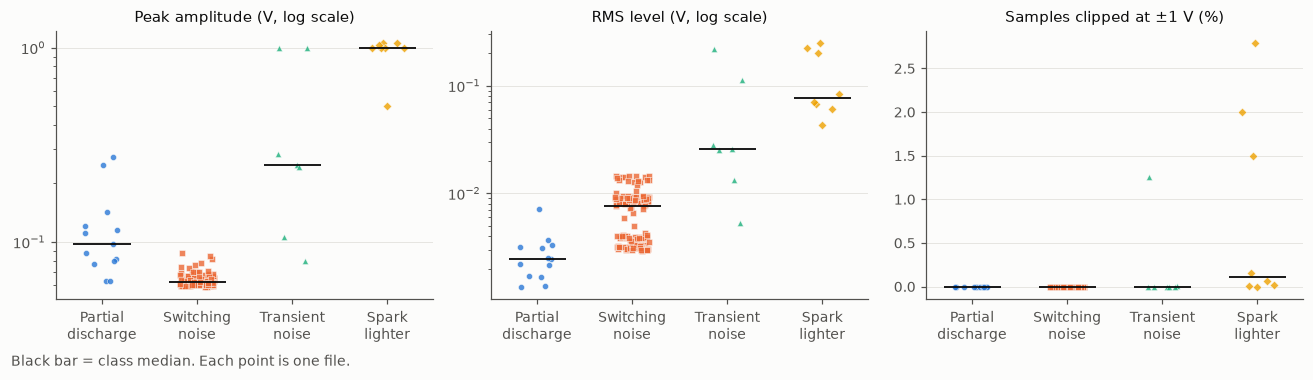

In [12]:
D = X - baseline[:, None]
df["peak_V"] = np.abs(D).max(axis=1)
df["rms_V"] = np.sqrt((D ** 2).mean(axis=1))
df["crest"] = df["peak_V"] / df["rms_V"]
df["clipped_pct"] = (np.abs(X) >= 0.999).mean(axis=1) * 100

def strip(ax, col, log=False):
    rng = np.random.default_rng(0)
    for i, c in enumerate(CLASSES):
        v = df.loc[df["label"] == c, col].values
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=16, color=COLORS[c],
                   marker=MARKERS[c], alpha=0.8, edgecolor="#fcfcfb", linewidth=0.4, zorder=3)
        ax.hlines(np.median(v), i - 0.3, i + 0.3, color=INK, linewidth=1.2, zorder=4)
    ax.set_xticks(range(len(CLASSES)), [NAMES[c].replace(" ", "\n") for c in CLASSES])
    ax.grid(axis="x", visible=False)
    if log: ax.set_yscale("log")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
strip(axes[0], "peak_V", log=True);  axes[0].set_title("Peak amplitude (V, log scale)")
strip(axes[1], "rms_V", log=True);   axes[1].set_title("RMS level (V, log scale)")
strip(axes[2], "clipped_pct");       axes[2].set_title("Samples clipped at ±1 V (%)")
fig.text(0.01, -0.02, "Black bar = class median. Each point is one file.", color=INK2)
plt.tight_layout(); plt.show()

**Explanation:**
- Amplitude alone separates the classes quite well: **switching noise ≈ 0.06 V** (very tight), **PD ≈ 0.06–0.27 V**, **transient noise 0.08–1 V**, **spark lighter ≈ 1 V (clipped)**.
- Switching noise and the weakest PD files have **the same peak height (~0.06 V)**. That is probably the oscilloscope's trigger threshold, so peak height cannot tell these two apart. Shape (next part) can.
- Clipping happens **only for spark lighter** (and one transient file). Clipping is a strong clue, but it is a side effect of the hardware range. If the gain changes later, this clue may disappear, so the model should not depend on it alone.

## 7. Shape: is it one sharp spike or a long burst?

The **crest factor = peak / RMS**. It is high when the energy is packed into one short spike and low when the energy is spread across the window.

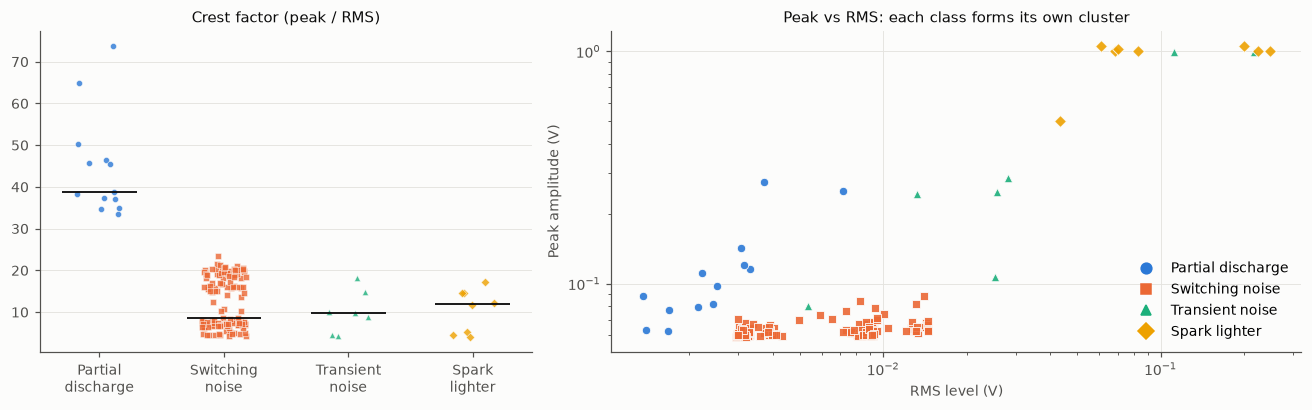

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
strip(axes[0], "crest"); axes[0].set_title("Crest factor (peak / RMS)")

ax = axes[1]
for c in CLASSES:
    g = df[df["label"] == c]
    ax.scatter(g["rms_V"], g["peak_V"], s=30, color=COLORS[c], marker=MARKERS[c],
               edgecolor="#fcfcfb", linewidth=0.6, alpha=0.9, label=NAMES[c], zorder=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("RMS level (V)"); ax.set_ylabel("Peak amplitude (V)")
ax.set_title("Peak vs RMS: each class forms its own cluster")
ax.legend(handles=legend_handles(), loc="lower right")
plt.tight_layout(); plt.show()

**Explanation:**
- **Partial discharge has by far the highest crest factor (~35–75)**: one sharp spike in an otherwise quiet window. The other classes are mostly 4–23.
- In the peak-vs-RMS plot **PD sits apart from switching noise even where their peaks match**, because PD has much less energy in the rest of the window. Two simple numbers already split the four classes into fairly separate clusters, which is a good sign for classification.

## 8. Frequency content

The FFT of each file shows which frequencies the signal contains (0 to 62.5 MHz, the Nyquist limit). The plot shows the **median spectrum per class**, normalised so each class peaks at 0 dB.

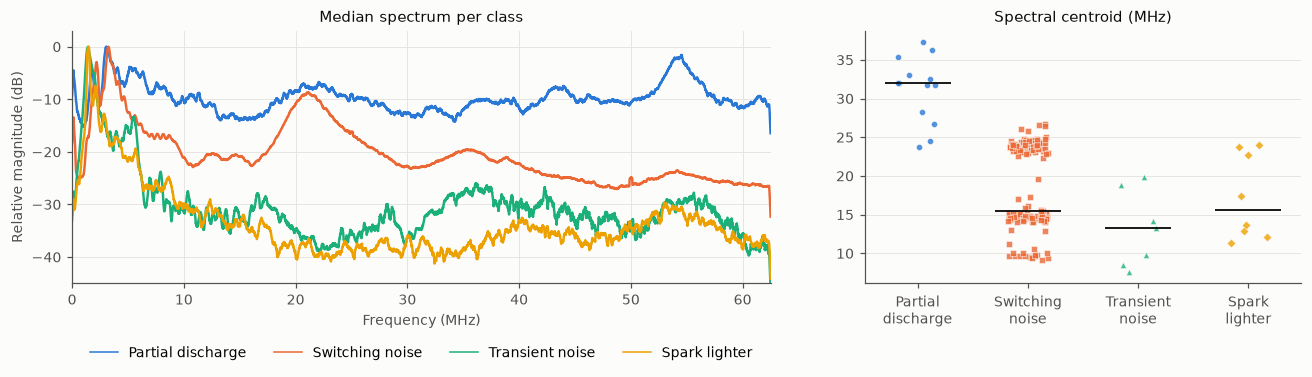

In [14]:
F = np.abs(np.fft.rfft(D, axis=1))
f_mhz = np.fft.rfftfreq(X.shape[1], 1 / FS) / 1e6
df["centroid_MHz"] = (F * f_mhz).sum(axis=1) / F.sum(axis=1)

def smooth(y, k=33):
    return np.convolve(y, np.ones(k) / k, mode="same")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
for c in CLASSES:
    s = smooth(np.median(F[(df["label"] == c).values], axis=0))
    ax.plot(f_mhz, 20 * np.log10(s / s.max()), color=COLORS[c], linewidth=1.6, label=NAMES[c])
ax.set_xlim(0, 62.5); ax.set_ylim(-45, 3)
ax.set_xlabel("Frequency (MHz)"); ax.set_ylabel("Relative magnitude (dB)")
ax.set_title("Median spectrum per class")
ax.legend(handles=legend_handles(marker=False), loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)

strip(axes[1], "centroid_MHz"); axes[1].set_title("Spectral centroid (MHz)")
plt.tight_layout(); plt.show()

**Explanation:**
- **Partial discharge has the most high-frequency energy.** Its spectrum stays flat far into the tens of MHz, and its spectral centroid (the "average frequency") is about 31 MHz, against about 13–18 MHz for the others. This fits a very fast, short pulse.
- **Switching noise** has clear peaks at about 3 MHz and about 21 MHz, then falls off.
- **Transient noise** and **spark lighter** carry most of their energy below ~5 MHz (peaking around 1–3 MHz) and are 30–40 dB weaker above 10 MHz. This matches the slow, large ringing seen in Part 4.

Frequency features, or a model that learns from them (for example a 1-D CNN), should help separate PD from the noise classes.

## 9. Time–frequency view (spectrograms)

A spectrogram shows **which frequencies are present at each moment**. One example per class (the middle file by time), over the first 20 µs after the trigger.

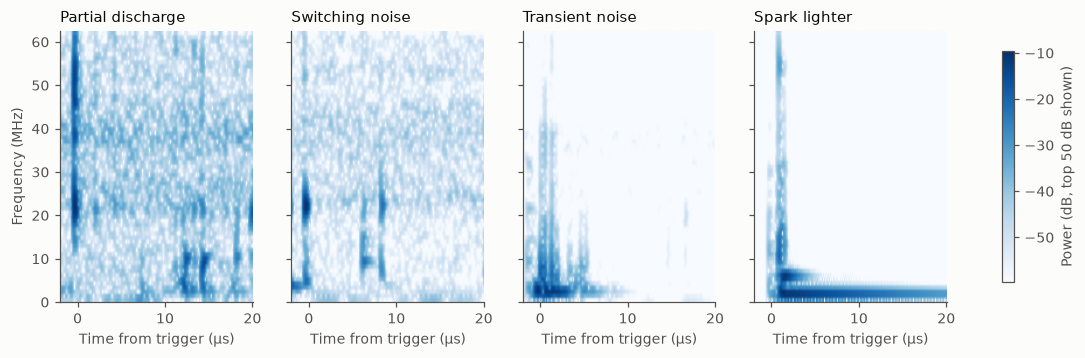

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
seg = slice(8192 - 256, 8192 + 2500)
for ax, c in zip(axes, CLASSES):
    idx = np.flatnonzero((df["label"] == c).values)
    x = D[idx[len(idx) // 2], seg]
    Pxx, fr, tt, im = ax.specgram(x, NFFT=128, Fs=FS / 1e6, noverlap=112, cmap="Blues",
                                  scale="dB", xextent=(-2, len(x) / (FS / 1e6) - 2))
    top = 10 * np.log10(Pxx.max())
    im.set_clim(top - 50, top)
    ax.set_title(NAMES[c], loc="left")
    ax.set_xlabel("Time from trigger (µs)")
    ax.grid(False)
axes[0].set_ylabel("Frequency (MHz)")
fig.colorbar(im, ax=axes, shrink=0.85, label="Power (dB, top 50 dB shown)")
plt.show()

**Explanation:** darker means more energy.
- **PD** shows thin vertical stripes: very brief events that cover the whole 0–60 MHz range at once (the broadband spike, plus a few smaller later pulses).
- **Switching noise** shows short bursts concentrated in bands around ~22 MHz and below 10 MHz, rather than full-height stripes.
- **Transient noise** puts its energy at low frequency (~2–3 MHz) and fades within about 8 µs.
- **Spark lighter** starts with a broadband flash, then holds a strong ~2 MHz tone for the whole 20 µs shown.

Spectrograms are another possible input format for a model (a 2-D image instead of a 1-D signal).

## 10. Summary and what it means for modelling

In [16]:
feat = ["peak_V", "rms_V", "crest", "clipped_pct", "centroid_MHz"]
tbl = df.groupby("label", observed=True)[feat].median()
tbl.insert(0, "files", df["label"].value_counts().reindex(CLASSES).values)
tbl.index = [NAMES[c] for c in tbl.index]
tbl.round(3)

,files,peak_V,rms_V,crest,clipped_pct,centroid_MHz
Partial discharge,13,0.097,0.002,38.727,0.00,32.030
Switching noise,139,0.062,0.008,8.557,0.00,15.488
Transient noise,7,0.249,0.026,9.693,0.00,13.310
Spark lighter,8,1.001,0.077,11.841,0.11,15.546


| Class | In one sentence |
|---|---|
| **Partial discharge** | Short, sharp, broadband spike (high crest factor, high frequency) in a quiet window. |
| **Switching noise** | Bursts repeating every ~33 µs, ~0.06 V, peaks near 3 and 21 MHz. Consistent within a session, different between sessions. |
| **Transient noise** | Larger, low-frequency (~2 MHz) ringing that decays within a few µs. Size varies a lot. |
| **Spark lighter** | Very large event that saturates the ±1 V input and rings at low frequency. |

**Takeaways for the next steps**
1. **Class imbalance (139 vs 7–13).** Use class weights or resampling, and report macro-F1 or a confusion matrix, not accuracy.
2. **Split by recording session, not by file.** Many switching-noise files are near-duplicates from 1-second bursts, and each session has its own signature (Part 5b), so a random split would leak and overstate performance.
3. **Waveforms are already aligned on sample 8192.** A model can use the full window or a crop around the trigger.
4. **The classes look separable.** Even simple features (peak, RMS, crest factor, spectral centroid) form clear clusters, so a simple feature-based baseline (for example logistic regression or a random forest) is worth trying before a CNN.
5. **Be careful with amplitude clues.** Clipping and the ~0.06 V trigger threshold come from the hardware settings. Consider training on normalised waveforms as well, so the model also learns shape.
6. **More data is needed most for transient noise and spark lighter**, which vary a lot but have very few examples.